# 50 — Sonic (choked) blowdown through a 10 mm pipe: air and CO₂

A 1 L supply container at **50 bar**, 20 °C, a **10 mm** bore pipe (100 mm long), a valve 20 mm down the pipe that
opens at t = 0 and stays open for the **10 ms** that are simulated, still air at 1 atm outside. Pressure ratio 50 ≫ the
critical ~1.9: the pipe chokes, its exit runs at Mach 1, the jet outside is under-expanded.

1. **CAD** (Dedalus / CadQuery): the rig and the fluid volume, from one `Rig` profile
2. **CFD** (OpenFOAM v2412 `rhoCentralFoam`, axisymmetric wedge, k-ω SST): time-dependent blowdown for each gas
3. **0-D model**: ideal gas and real gas (CoolProp) through a choked throat
4. **Plots**: exit velocity vs time, mass flow, Mach, pressures, temperatures, released mass, Mach fields

Code: `sonic_flow.py` (CAD, case, 0-D) and `sonic_flow_report.py` (plots). Shell: `python sonic_flow.py run --processors 2`
then `python sonic_flow.py report`.

In [1]:
DEBUG = False                                  # real OpenFOAM runs (no mocks) when RUN_CFD is True
from vegeta.labkit import bootstrap
DEBUG = bootstrap.lab("aero", DEBUG)
RUN_CFD = False                                # True: write and solve both cases (~30 min on 2+2 cores)
import json
from pathlib import Path
from IPython.display import Image, display
import sonic_flow as sf, sonic_flow_report as rep
CASES, RESULTS = Path("output/sonic_flow"), Path("sonic_flow_results")
rig, cond = sf.Rig(), sf.Conditions()
rig, cond, rig.container_length

(Rig(pipe_bore=10.0, pipe_length=100.0, pipe_wall=2.0, valve_x=20.0, container_volume_l=1.0, container_bore=100.0, container_wall=5.0, ambient_length=200.0, ambient_radius=100.0),
 Conditions(p0=5000000.0, T0=293.15, p_amb=101325.0, T_amb=293.15, end_time=0.01, write_interval=0.0005, cfl=0.4),
 127.32395447351627)

## 1. CAD — the rig and the gas it holds

fluid volume 1.0079 L (expected 1.0079 L)


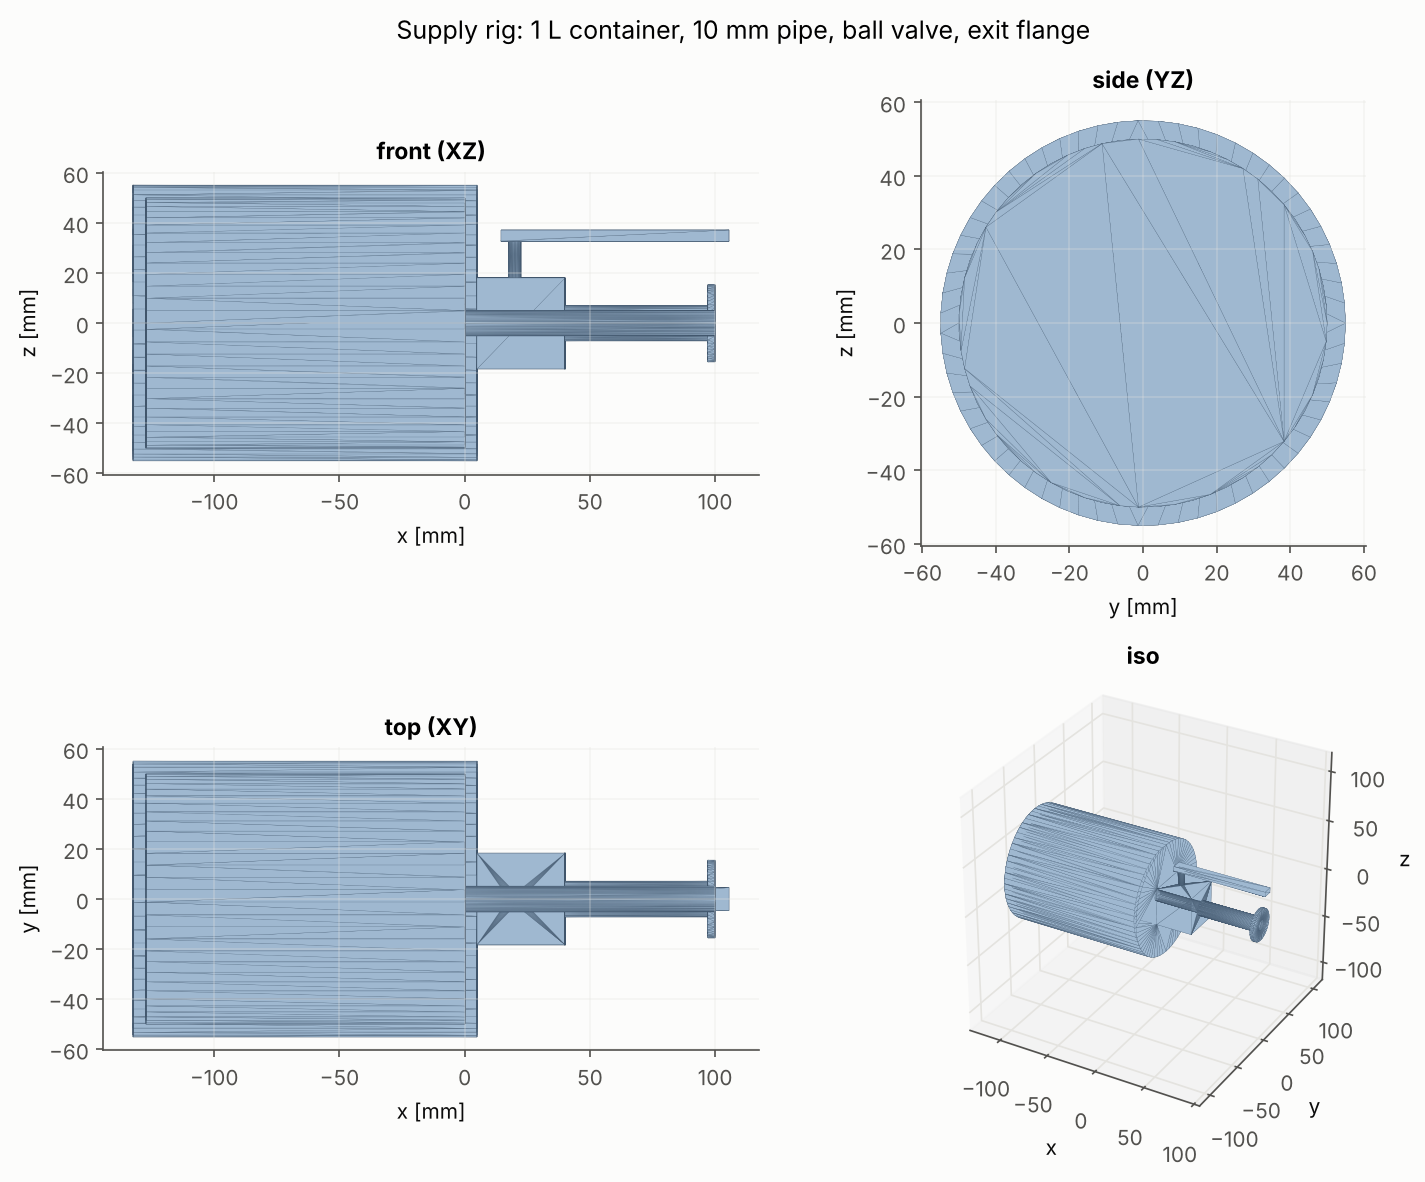

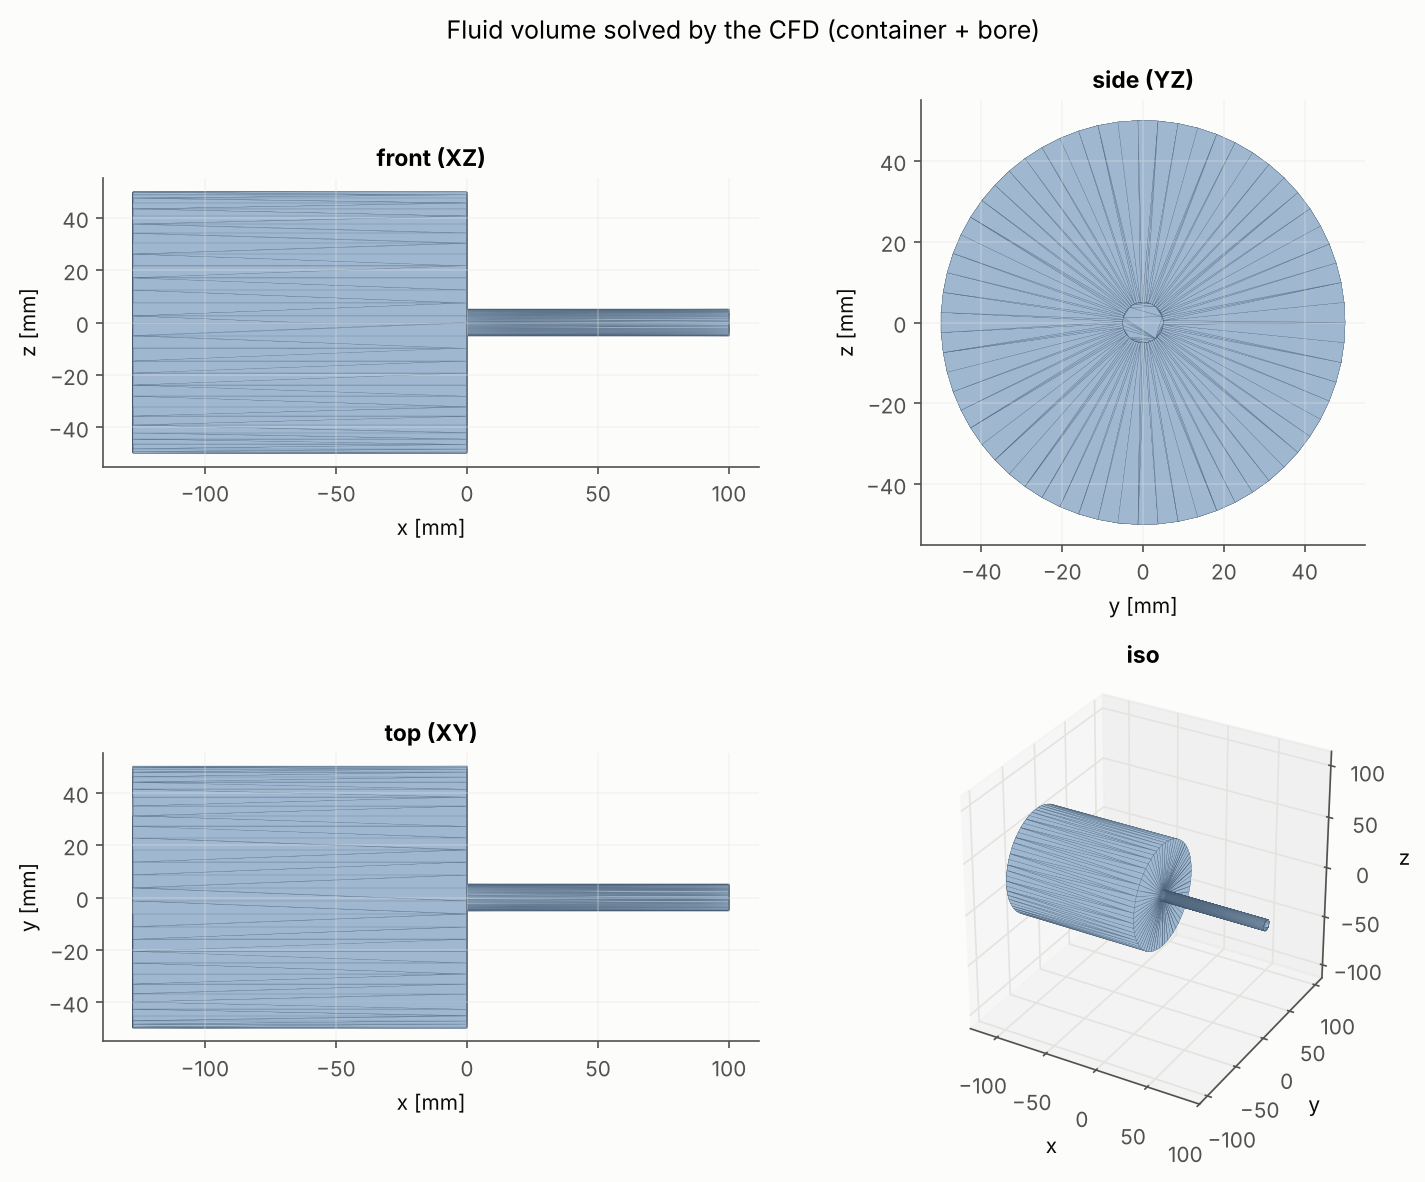

In [2]:
cad = sf.make_cad(RESULTS / "cad", rig)
print(f"fluid volume {cad['fluid_volume_l']:.4f} L (expected {cad['fluid_volume_expected_l']:.4f} L)")
rep.plot_cad(RESULTS / "cad", RESULTS)
display(Image(RESULTS / "cad_supply_rig.png"), Image(RESULTS / "cad_fluid_volume.png"))

## 2. CFD — rhoCentralFoam, one case per gas

Wedge of 5°, 0.5 mm cells in the bore, graded out to 4–5 mm in the container and the ambient. The valve is a
diaphragm: everything up to its seat starts at 50 bar (`setFields`) and the flow starts at t = 0. The step is fixed
from the in-plane CFL (`sf.time_step`).

In [3]:
for g in ("air", "co2"):
    print(g, "gamma = %.3f" % sf.GASES[g].gamma, "dt = %.3g s" % sf.time_step(sf.GASES[g], cond, sf.Mesh()))
if RUN_CFD:
    for g in ("air", "co2"):
        sf.run_case(sf.write_case(CASES / g, sf.GASES[g], rig, cond), processors=2)

air gamma = 1.400 dt = 1.8e-07 s
co2 gamma = 1.288 dt = 2.06e-07 s


## 3. 0-D model — choked throat, ideal and real gas

In [4]:
for g in ("air", "co2"):
    G, U, ps, Ts = sf.choked_ideal(sf.GASES[g], cond.p0, cond.T0)
    Gr, Ur, psr, Tsr, q = sf.choked_real(sf.GASES[g].coolprop, cond.p0, cond.T0)
    print(f"{g:4s} ideal: u* {U:6.1f} m/s  p* {ps/1e5:5.1f} bar  T* {Ts:5.1f} K | real: u* {Ur:6.1f} m/s  "
          f"p* {psr/1e5:5.1f} bar  T* {Tsr:5.1f} K  vapour quality {q}")

air  ideal: u*  313.4 m/s  p*  26.4 bar  T* 244.3 K | real: u*  312.7 m/s  p*  26.1 bar  T* 242.1 K  vapour quality None
co2  ideal: u*  249.7 m/s  p*  27.4 bar  T* 256.3 K | real: u*  187.2 m/s  p*  30.1 bar  T* 267.7 K  vapour quality 0.924116434999797


## 4. Results

In [5]:
summary = rep.report(CASES, RESULTS, ("air", "co2"), cond)
print(json.dumps(summary["cfd"], indent=1))

{
 "air": {
  "gas": "air",
  "end_time_ms": 9.9999617,
  "exit_velocity_peak_m_s": 544.058071,
  "exit_velocity_end_m_s": 373.556238,
  "exit_velocity_mean_2nd_half_m_s": 378.8072439539824,
  "exit_mach_end": 1.29490577,
  "exit_pressure_end_bar": 13.311588400000002,
  "exit_temperature_end_K": 207.760382,
  "mass_flow_peak_kg_s": 0.764203716,
  "mass_flow_end_kg_s": 0.65202677568,
  "released_mass_g": 6.9191782804468795,
  "container_pressure_end_bar": 41.920719500000004,
  "container_temperature_end_K": 278.756238,
  "container_mass_start_g": 59.33251044,
  "container_mass_end_g": 52.313732783999995,
  "first_choked_ms": 0.11000444000000001,
  "choked_fraction": 0.9890175179590588
 },
 "co2": {
  "gas": "co2",
  "end_time_ms": 10.000079,
  "exit_velocity_peak_m_s": 460.86882,
  "exit_velocity_end_m_s": 303.583037,
  "exit_velocity_mean_2nd_half_m_s": 305.5118679718627,
  "exit_mach_end": 1.2864981,
  "exit_pressure_end_bar": 15.0341779,
  "exit_temperature_end_K": 229.989558,
  "mas

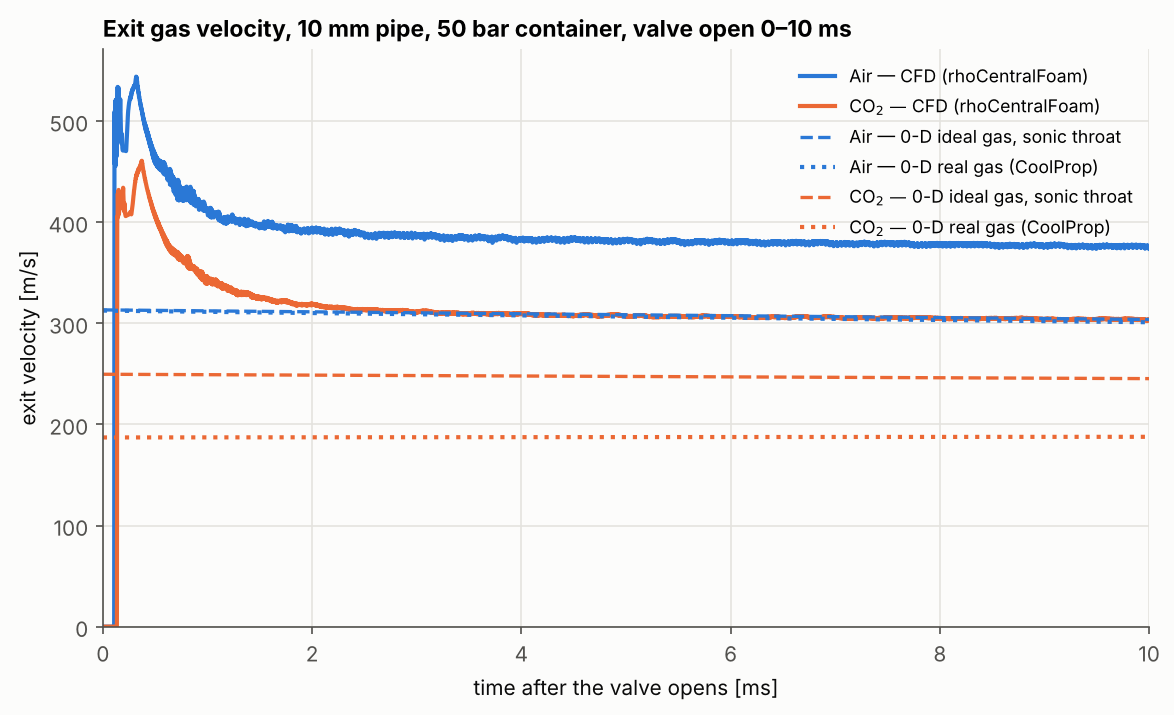

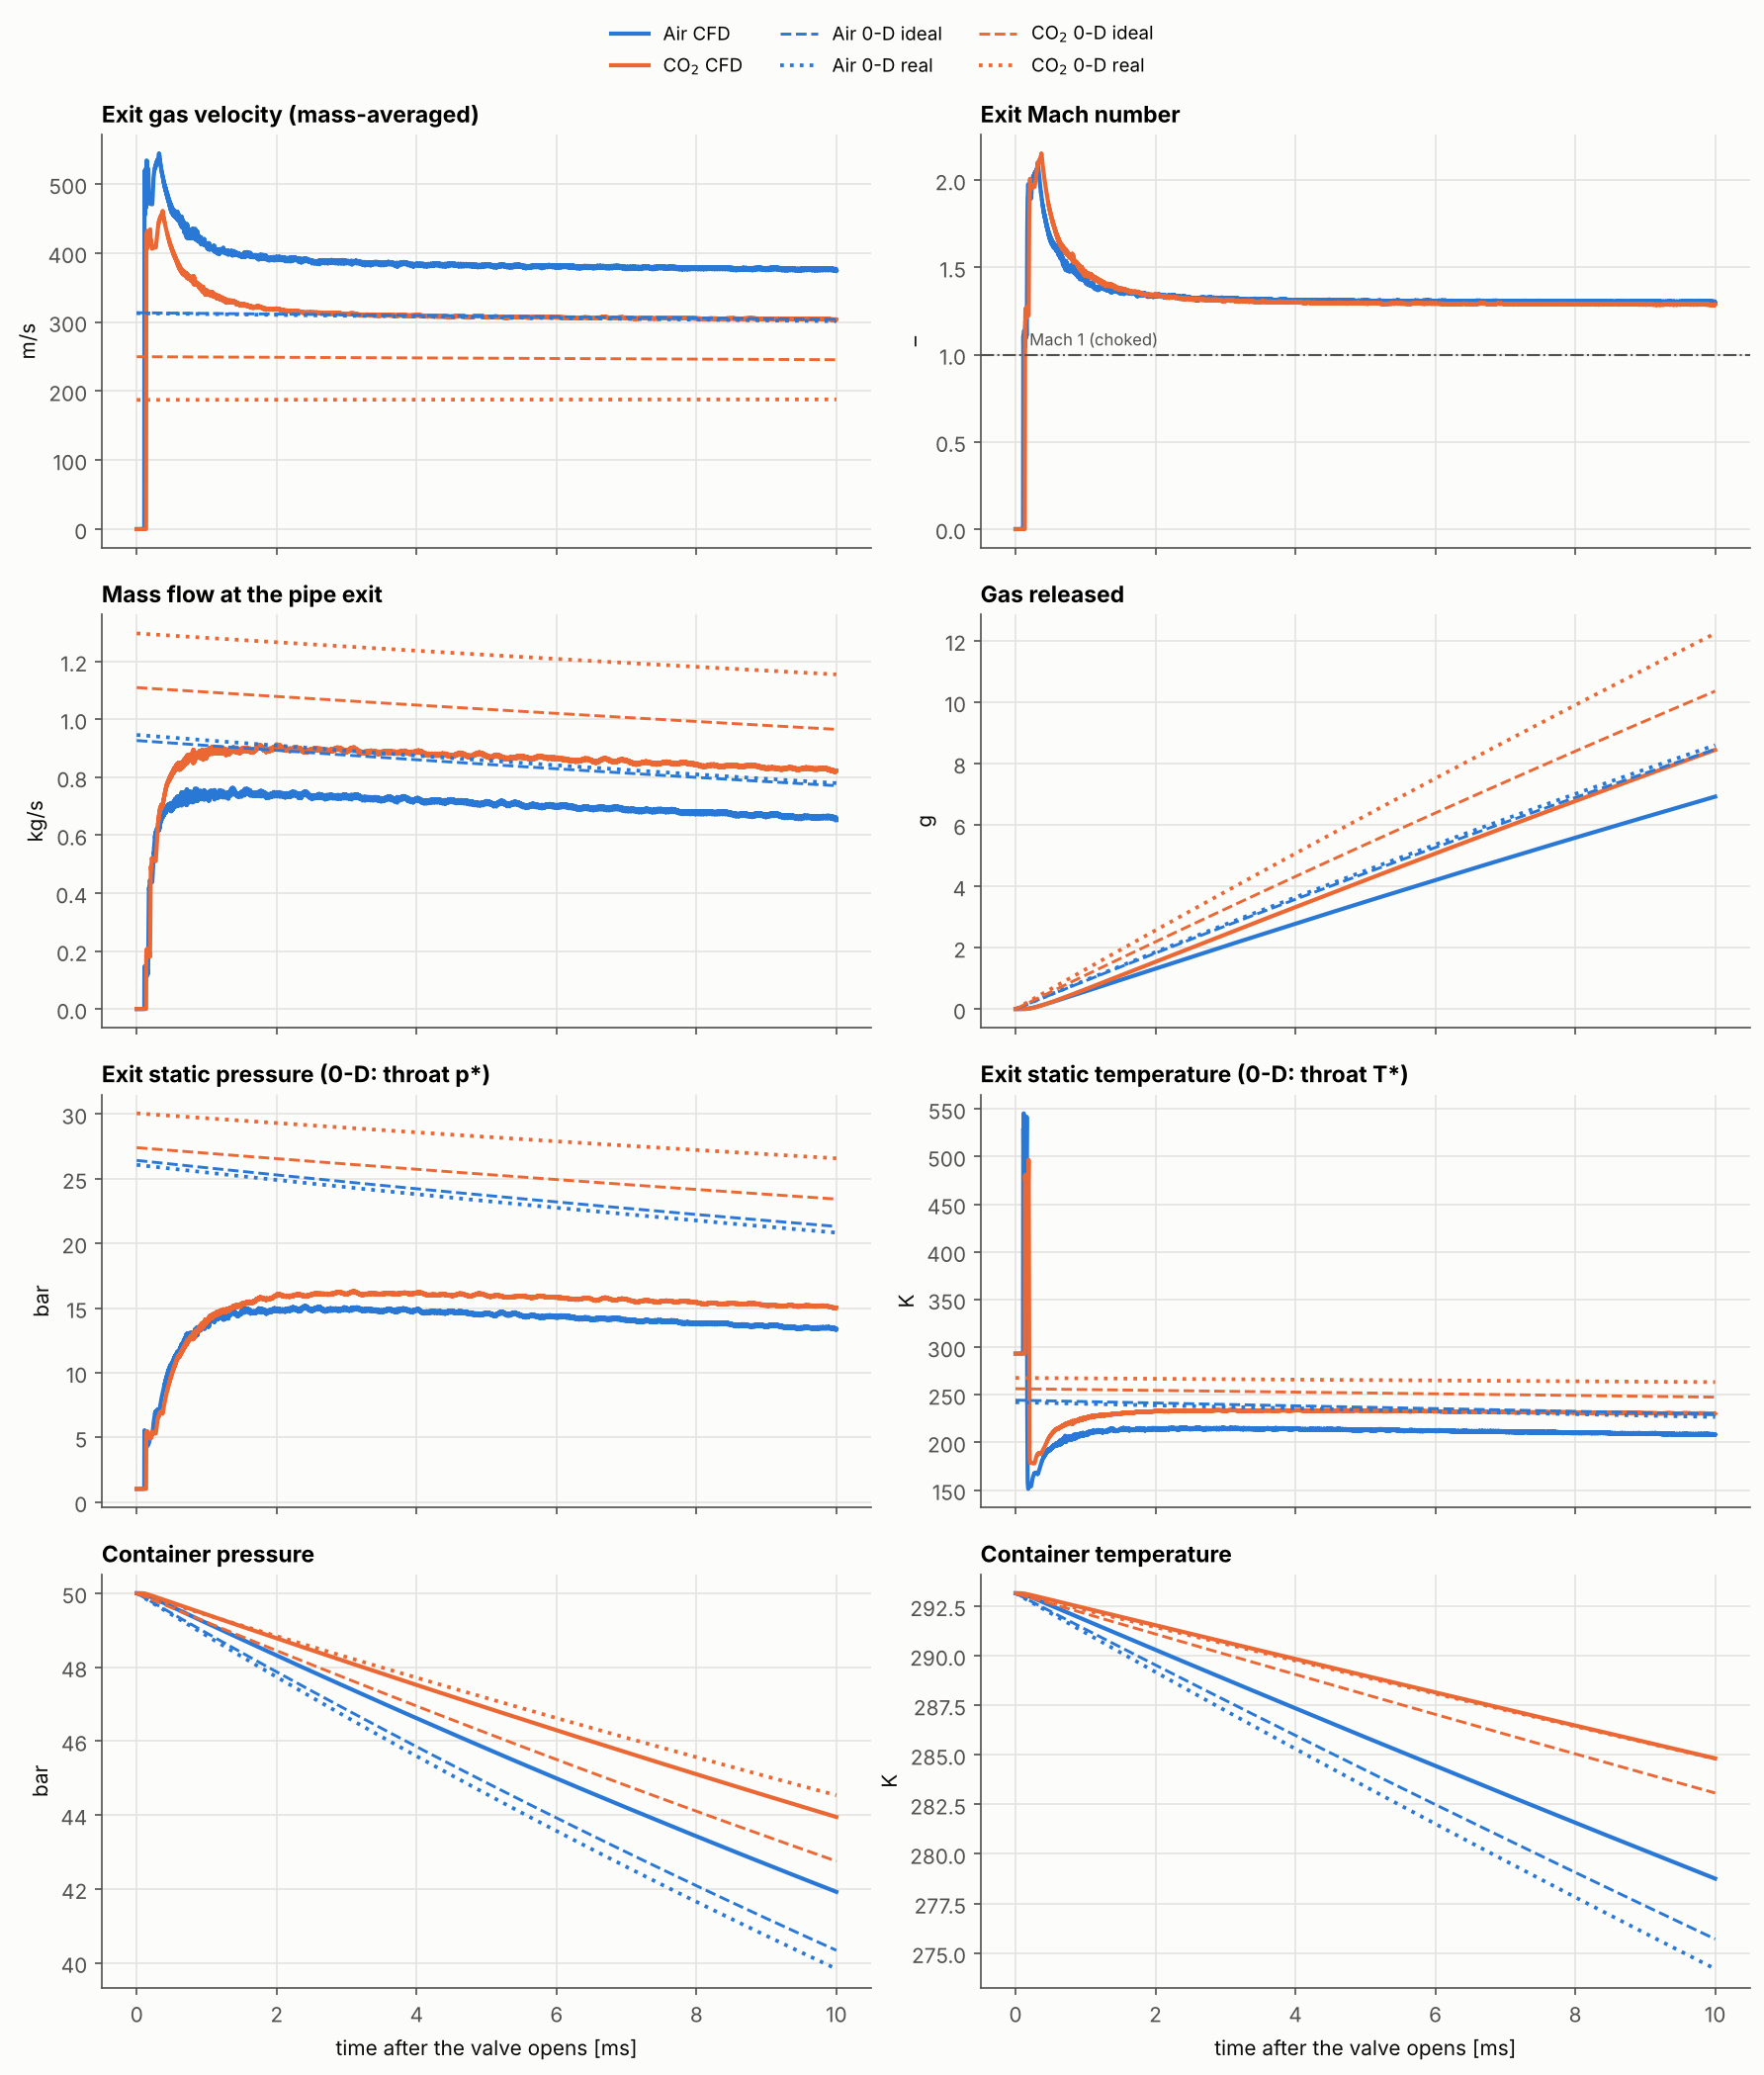

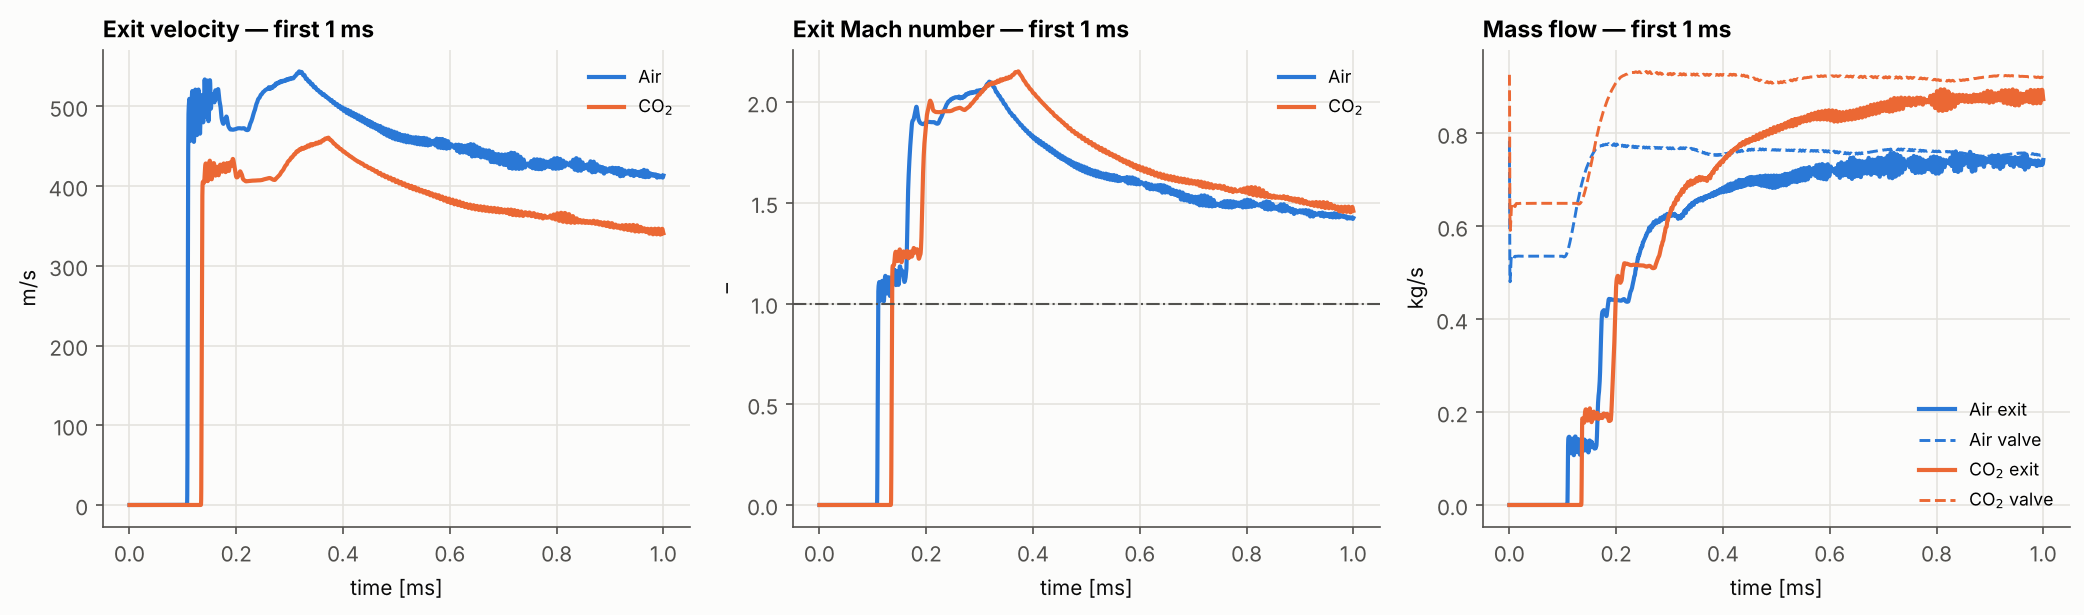

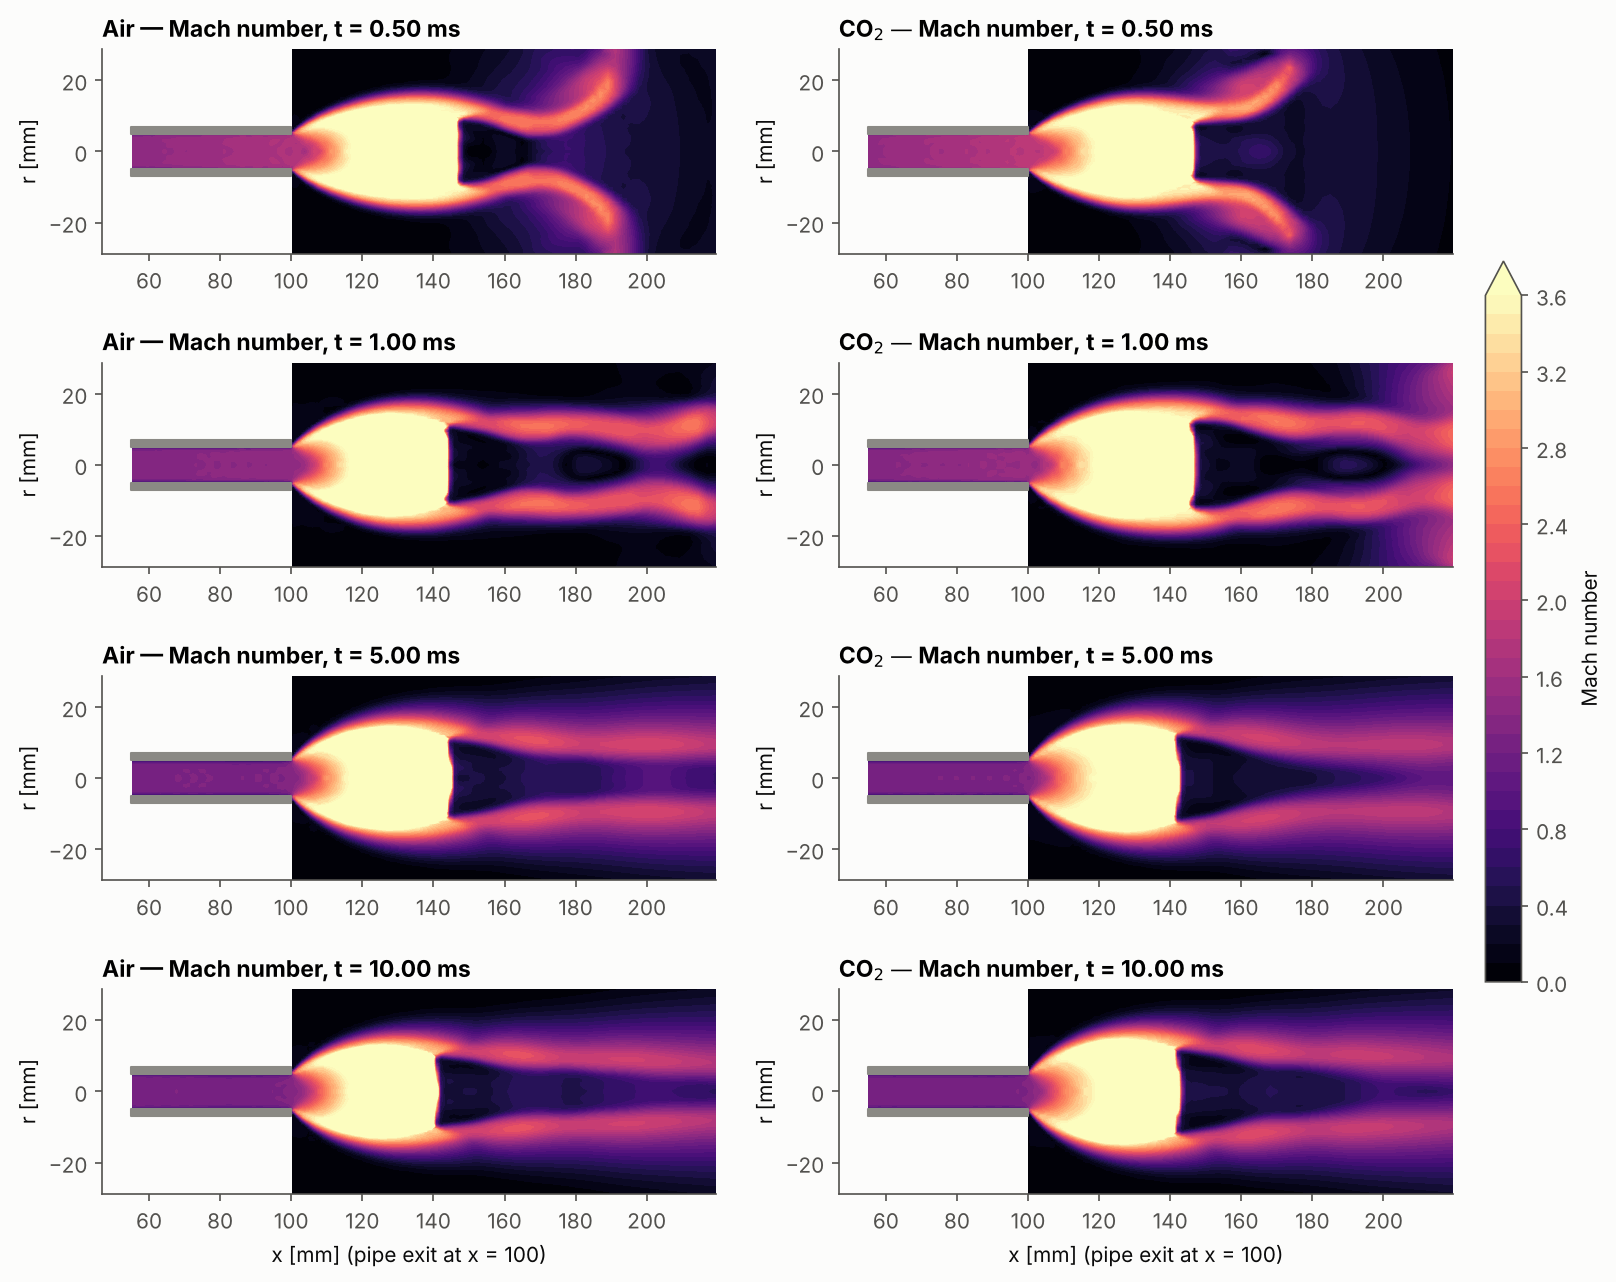

In [6]:
for f in ("exit_velocity", "blowdown_dashboard", "startup_transient", "mach_fields"):
    display(Image(RESULTS / f"{f}.png"))

## Reading it

See `sonic_flow_results/README.md` for the numbers and the discussion: the start-up (shock-tube) overshoot, the choked
plateau, the decay with the container, friction and the vena contracta against the ideal nozzle, and why CO₂ at
50 bar needs the real-gas model (Z ≈ 0.64 in the container, condensation at the throat).